In [1]:
import pandas as pd


In [2]:
columns = [
    "id",
    "diagnosis",
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave_points_mean",
    "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se",
    "texture_se",
    "perimeter_se",
    "area_se",
    "smoothness_se",
    "compactness_se",
    "concavity_se",
    "concave_points_se",
    "symmetry_se",
    "fractal_dimension_se",
    "radius_worst",
    "texture_worst",
    "perimeter_worst",
    "area_worst",
    "smoothness_worst",
    "compactness_worst",
    "concavity_worst",
    "concave_points_worst",
    "symmetry_worst",
    "fractal_dimension_worst"
]

df = pd.read_csv('wdbc.data',header=None,names=columns)


In [3]:
print(df.shape)
print("*******")
print(df.info())

(569, 32)
*******
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se       

In [4]:
df["diagnosis"] = df["diagnosis"].map({
    "M": 1,
    "B": 0
})

In [5]:
X = df.drop(columns=['diagnosis','id'])
y = df['diagnosis']


In [6]:

print(df['diagnosis'].value_counts())


print(df['diagnosis'].value_counts(normalize=True) * 100)

diagnosis
0    357
1    212
Name: count, dtype: int64
diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


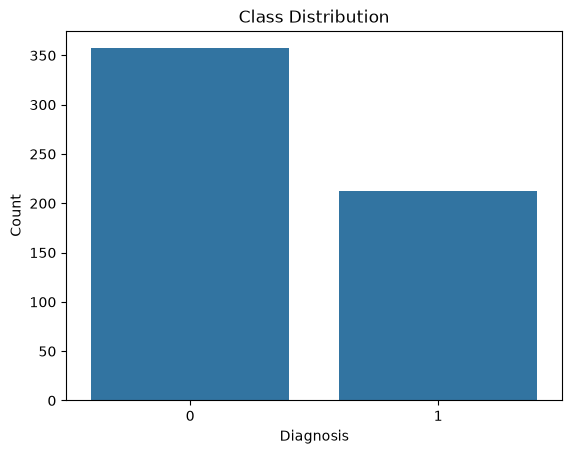

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='diagnosis')

plt.title('Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# 80% Train ، 20% Test  (نسبت رایج و مناسب برای این دیتاست)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size :", X_test.shape[0])

print("\nTrain distribution:")
print(y_train.value_counts(normalize=True).round(3) * 100)

print("\nTest distribution:")
print(y_test.value_counts(normalize=True).round(3) * 100)

Train size: 455
Test size : 114

Train distribution:
diagnosis
0    62.6
1    37.4
Name: proportion, dtype: float64

Test distribution:
diagnosis
0    63.2
1    36.8
Name: proportion, dtype: float64


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

parameters = {
    "criterion": ["gini", "entropy"],
    "max_depth" : [2, 3, 4, 5, 6, 7, 8, 10]
}

dt_grid = GridSearchCV(
    estimator = DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_grid = parameters,
    scoring= "f1",
    cv=5
)

dt_grid.fit(X_train, y_train)
y_test_pred = dt_grid.predict(X_test)

best_val_f1 = dt_grid.best_score_
best_depth = dt_grid.best_params_


print("\nBest max_depth:", best_depth)
print("Best Validation f1:", best_val_f1)


Best max_depth: {'criterion': 'entropy', 'max_depth': 5}
Best Validation f1: 0.9051816108467976


In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_pred
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[71  1]
 [ 8 34]]


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)


rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}


rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_params,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)


rf_test_pred = rf_grid.predict(X_test)

print("Best Parameters:", rf_grid.best_params_)
print("Best CV F1 Score:", rf_grid.best_score_)

print("\nTest Accuracy:",
      accuracy_score(y_test, rf_test_pred))

print("Test Precision:",
      precision_score(y_test, rf_test_pred, zero_division=0))

print("Test Recall:",
      recall_score(y_test, rf_test_pred, zero_division=0))

print("Test F1 Score:",
      f1_score(y_test, rf_test_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1 Score: 0.9592013212343892

Test Accuracy: 0.9649122807017544
Test Precision: 0.975
Test Recall: 0.9285714285714286
Test F1 Score: 0.9512195121951219

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Confusion Matrix:
[[71  1]
 [ 3 39]]


In [12]:
from sklearn.ensemble import GradientBoostingClassifier


gb = GradientBoostingClassifier(
    random_state=42,
)


gb_params = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "subsample": [0.8, 1.0]
}


gb_grid = GridSearchCV(
    estimator=gb,
    param_grid=gb_params,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)


gb_test_pred = gb_grid.predict(X_test)

print("Best Parameters:", gb_grid.best_params_)
print("Best CV F1 Score:", gb_grid.best_score_)

print("\nTest Accuracy:",
      accuracy_score(y_test, gb_test_pred))

print("Test Precision:",
      precision_score(y_test, gb_test_pred, zero_division=0))

print("Test Recall:",
      recall_score(y_test, gb_test_pred, zero_division=0))

print("Test F1 Score:",
      f1_score(y_test, gb_test_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_test_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, gb_test_pred))


Best Parameters: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 200, 'subsample': 0.8}
Best CV F1 Score: 0.9555540025624387

Test Accuracy: 0.9649122807017544
Test Precision: 1.0
Test Recall: 0.9047619047619048
Test F1 Score: 0.95

Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

Confusion Matrix:
[[72  0]
 [ 4 38]]


In [13]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred),
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, gb_test_pred)
    ],
    "Precision": [
        precision_score(y_test, y_test_pred, zero_division=0),
        precision_score(y_test, rf_test_pred, zero_division=0),
        precision_score(y_test, gb_test_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, rf_test_pred, zero_division=0),
        recall_score(y_test, gb_test_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, rf_test_pred, zero_division=0),
        f1_score(y_test, gb_test_pred, zero_division=0)
    ]
})

print(results.sort_values(
    by="F1 Score",
    ascending=False
).round(4).to_string(index=False))

            Model  Accuracy  Precision  Recall  F1 Score
    Random Forest    0.9649     0.9750  0.9286    0.9512
Gradient Boosting    0.9649     1.0000  0.9048    0.9500
    Decision Tree    0.9211     0.9714  0.8095    0.8831


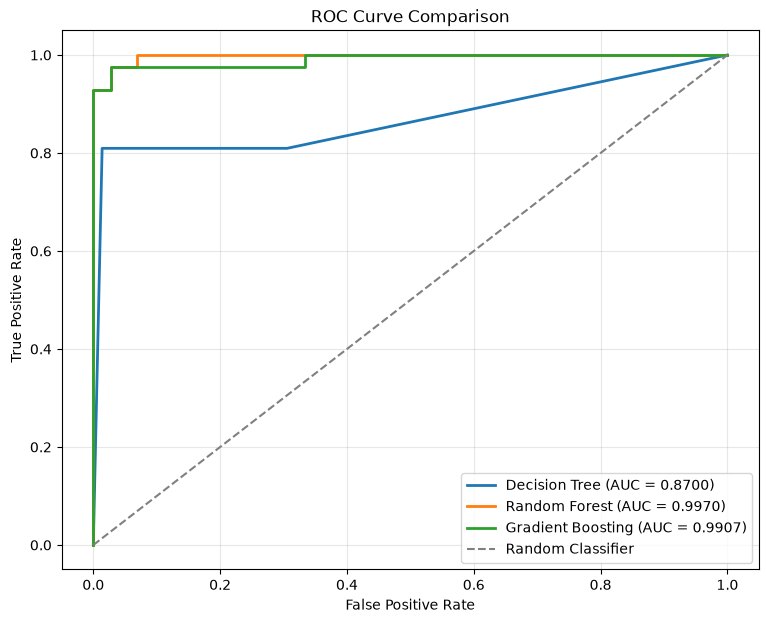

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


models = {
    "Decision Tree": dt_grid ,
    "Random Forest": rf_grid,
    "Gradient Boosting": gb_grid
}

plt.figure(figsize=(9, 7))

for name, model in models.items():


    y_proba = model.predict_proba(X_test)[:, 1]


    fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=1)


    auc_score = roc_auc_score(y_test, y_proba)


    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


In [16]:
# انتخاب مدل بر اساس CV (بدون وابستگی به سلول ۱۳)
grids = {
    "Decision Tree": dt_grid,
    "Random Forest": rf_grid,
    "Gradient Boosting": gb_grid
}

best_name = max(grids, key=lambda name: grids[name].best_score_)

final_model = grids[best_name].best_estimator_
best_params = grids[best_name].best_params_

print("Final model:", best_name)
print("Best Parameters:", best_params)

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

Final model: Random Forest
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


In [17]:
print("\n--- Best Hyperparameters ---")
for k, v in best_params.items():
    print(f"  {k}: {v}")

print("\n--- Performance on Test Set ---")
print(f"  Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  F1 Score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  ROC AUC  : {roc_auc_score(y_test, y_proba):.4f}")

print("\n--- Classification Report ---")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign (0)", "Malignant (1)"],
    zero_division=0
))

print("--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)


--- Best Hyperparameters ---
  max_depth: None
  min_samples_leaf: 2
  min_samples_split: 5
  n_estimators: 100

--- Performance on Test Set ---
  Accuracy : 0.9649
  Precision: 0.9750
  Recall   : 0.9286
  F1 Score : 0.9512
  ROC AUC  : 0.9970

--- Classification Report ---
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

--- Confusion Matrix ---
[[71  1]
 [ 3 39]]


In [18]:
feat_imp = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n--- Top 10 Important Features ---")
print(feat_imp.head(10).to_string(index=False))


--- Top 10 Important Features ---
             Feature  Importance
          area_worst    0.149020
concave_points_worst    0.116943
 concave_points_mean    0.108498
        radius_worst    0.082075
     perimeter_worst    0.081137
      concavity_mean    0.079778
      perimeter_mean    0.058849
           area_mean    0.050388
         radius_mean    0.047598
     concavity_worst    0.041026


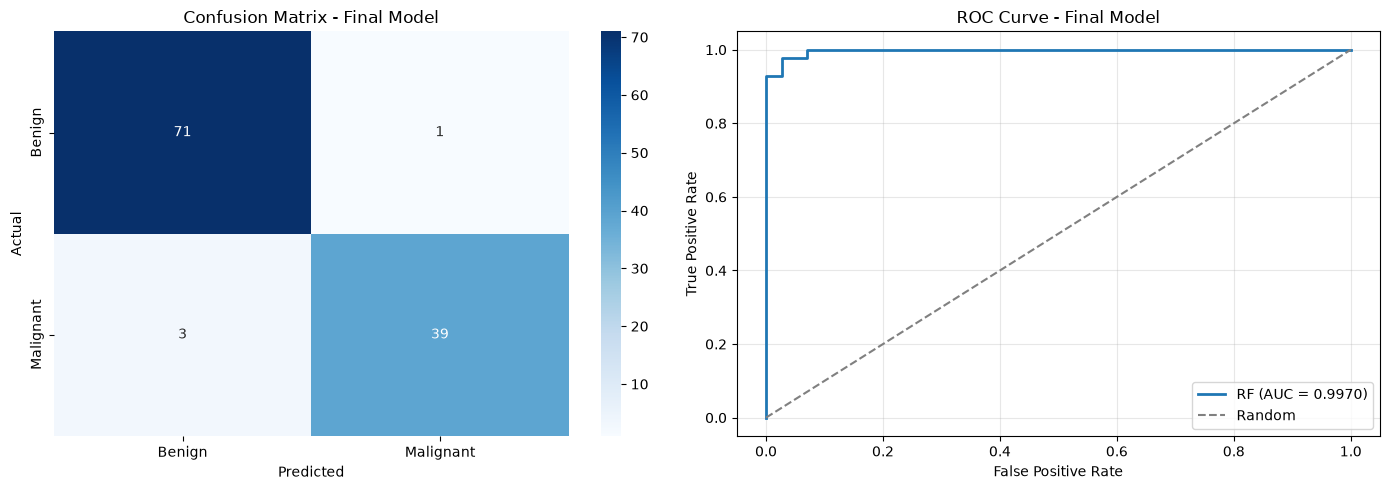

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    ax=axes[0]
)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix - Final Model")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=1)
auc = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, linewidth=2, label=f"RF (AUC = {auc:.4f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve - Final Model")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

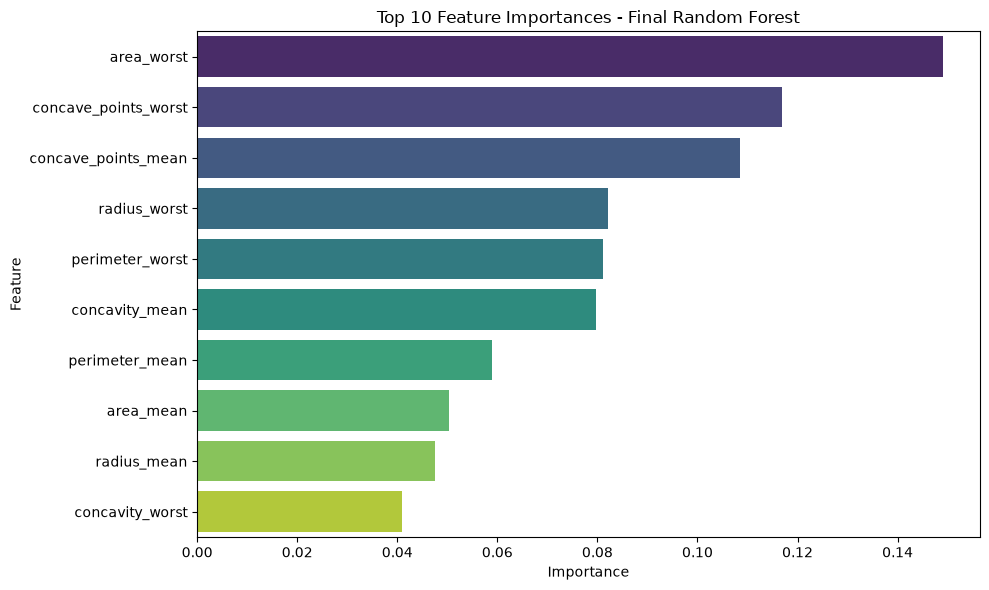

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feat_imp.head(10),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Feature Importances - Final Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [21]:
import joblib

joblib.dump(final_model, "final_rf_model.joblib")

['final_rf_model.joblib']